# Weather Forecasting Challenge

**Name:** Faeyza Safa Izz Deyardi  
**NIM:** 255150207111060

Target forecasting adalah `target_temperature_6h_c`, yaitu temperatur enam jam ke depan. Semua evaluasi menggunakan urutan waktu dan hanya memakai model linear yang diizinkan.

This notebook follows the official assessment template. Markdown explanation is placed before each code block, while results, tables, and charts are generated from `weather.csv` when the notebook is run.

### Preserved preliminary benchmark

Eksperimen chronological holdout 80/20 sebelumnya tetap dicatat: Ridge RMSE 0.893393, Linear Regression 0.893480, Lasso 0.893521, dan Elastic Net 0.893534. Benchmark tersebut tidak dihapus, tetapi eksperimen utama di bawah memakai train/validation/test terpisah agar test set tetap independen.

## Setup

Memuat library, membaca data, memparse timestamp, serta menerapkan clipping anomali fisik sebelum EDA dan feature engineering. Model yang diimpor hanya Linear Regression, Ridge, Lasso, dan Elastic Net.

### Menjalankan di Google Colab

Cell Setup memuat `weather.csv` dengan urutan berikut:

1. **Working directory:** jika `weather.csv` sudah berada di folder kerja saat ini (baik lokal maupun sesi Colab), file itu langsung digunakan.
2. **Google Drive (opsional, hanya Colab):** jika file belum ada, cell akan me-mount Google Drive dan mencari file pada `DRIVE_DATASET_PATH`. Ubah placeholder variabel tersebut sesuai folder Drive Anda sebelum menjalankan cell.
3. **Upload manual (fallback terakhir, hanya Colab):** jika file tidak ditemukan di Drive, Colab akan menampilkan pemilih file untuk upload CSV.

Untuk VS Code/lokal, jalankan notebook dari root repository atau dari folder `notebooks/`; dataset akan dibaca dari `data/weather.csv`. Tidak ada path desktop atau path Google Drive pribadi yang disimpan di notebook.

In [1]:
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Environment and dataset configuration. Keep this placeholder relative to Google Drive;
# edit it only when you want to load a persistent copy from your own Drive.
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DATA_FILE = Path('data/weather.csv') if Path('data/weather.csv').exists() else Path('../data/weather.csv')
DRIVE_DATASET_PATH = 'MyDrive/ML-Assessment/weather.csv'  # Change to your own Drive-relative dataset path when needed.
method_used = None

# 1) Use a session/local working-directory file whenever it already exists.
if DATA_FILE.exists():
    method_used = 'local working directory'

# 2) In Colab only, optionally mount Drive and look for the configured relative path.
elif IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    drive_file = Path('/content/drive') / DRIVE_DATASET_PATH
    if drive_file.exists():
        DATA_FILE = drive_file
        method_used = 'Google Drive mount'

    # 3) Last fallback for Colab: interactive upload.
    else:
        from google.colab import files
        print('Dataset was not found in the working directory or configured Google Drive location. Please upload the CSV file.')
        uploaded = files.upload()
        csv_files = [Path(name) for name in uploaded if name.lower().endswith('.csv')]
        if Path('weather.csv') in csv_files:
            DATA_FILE = Path('data/weather.csv') if Path('data/weather.csv').exists() else Path('../data/weather.csv')
        elif len(csv_files) == 1:
            DATA_FILE = csv_files[0]
        else:
            raise FileNotFoundError('Upload exactly one CSV file, preferably named weather.csv, then re-run this cell.')
        method_used = 'manual upload'

# Local execution has no Drive/upload fallback by design.
else:
    raise FileNotFoundError('weather.csv was not found. Jalankan dari root repository atau folder notebooks agar data/weather.csv dapat ditemukan.')

print(f'Dataset dimuat via: {method_used} -> {DATA_FILE.name}')
TARGET = 'target_temperature_6h_c'
df_raw = pd.read_csv(DATA_FILE)
df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp'], format='%Y-%m-%d %H', errors='raise')

# Physical-range cleaning is performed before EDA and feature construction.
df_clean = df_raw.copy()
anomaly_before = {
    'humidity_outside_0_100': int(((df_clean['humidity_pct'] < 0) | (df_clean['humidity_pct'] > 100)).sum()),
    'negative_wind_speed': int((df_clean['wind_speed_ms'] < 0).sum()),
    'wind_direction_outside_0_359': int(((df_clean['wind_direction_deg'] < 0) | (df_clean['wind_direction_deg'] >= 360)).sum()),
}
df_clean['humidity_pct'] = df_clean['humidity_pct'].clip(0, 100)
df_clean['wind_speed_ms'] = df_clean['wind_speed_ms'].clip(lower=0)
df_clean['wind_direction_deg'] = df_clean['wind_direction_deg'] % 360

print(f'Rows x columns: {df_raw.shape[0]:,} x {df_raw.shape[1]}')
print(f'Timestamp range: {df_raw.timestamp.min()} to {df_raw.timestamp.max()}')
print('Columns:', df_raw.columns.tolist())
display(df_raw.head())
display(df_raw.dtypes.to_frame('dtype'))
display(df_raw.describe(include='all').T)
print('Physical anomalies before clipping:', anomaly_before)
print('Cleaning applied: humidity clipped to [0, 100], wind speed clipped at 0, and wind direction mapped with modulo 360.')

Dataset dimuat via: local working directory -> weather.csv
Rows x columns: 26,298 x 15
Timestamp range: 2023-01-01 00:00:00 to 2025-12-31 17:00:00
Columns: ['timestamp', 'temperature_c', 'humidity_pct', 'pressure_hpa', 'wind_speed_ms', 'wind_direction_deg', 'cloud_cover_pct', 'solar_radiation_wm2', 'precipitation_mm', 'dew_point_c', 'visibility_km', 'soil_moisture_pct', 'uv_index', 'feels_like_c', 'target_temperature_6h_c']


,timestamp,temperature_c,humidity_pct,pressure_hpa,wind_speed_ms,wind_direction_deg,cloud_cover_pct,solar_radiation_wm2,precipitation_mm,dew_point_c,visibility_km,soil_moisture_pct,uv_index,feels_like_c,target_temperature_6h_c
0,2023-01-01 00:00:00,23.9572,96.2405,1010.2277,2.3424,110.0000,61.1763,4.9450,0.0,23.3210,16.3343,46.0000,0.0000,24.9668,24.2328
1,2023-01-01 01:00:00,23.7844,94.3028,1010.3044,2.1672,104.8533,49.9464,0.0000,0.0,22.8130,15.8698,45.7561,0.0000,24.0902,26.5767
2,2023-01-01 02:00:00,23.4732,89.0114,1011.9373,2.8572,92.2816,41.3675,0.1392,0.0,21.5569,18.3136,45.5025,0.0186,23.8338,27.1729
3,2023-01-01 03:00:00,22.8376,95.6453,1012.4235,2.2598,99.1539,55.3739,14.9508,0.0,22.1049,18.2368,45.3322,0.2745,23.2009,26.9674
4,2023-01-01 04:00:00,23.7423,92.4213,1012.3489,2.0029,99.1621,47.7180,5.2828,0.0,22.4392,16.9622,45.0535,0.0000,24.4393,27.4036


,dtype
timestamp,datetime64[us]
temperature_c,float64
humidity_pct,float64
pressure_hpa,float64
wind_speed_ms,float64
wind_direction_deg,float64
cloud_cover_pct,float64
solar_radiation_wm2,float64
precipitation_mm,float64
dew_point_c,float64


,count,mean,min,25%,50%,75%,max,std
timestamp,26298,2024-07-01 20:30:00,2023-01-01 00:00:00,2023-10-01 22:15:00,2024-07-01 20:30:00,2025-04-01 18:45:00,2025-12-31 17:00:00,NaN
temperature_c,25882.0,26.462692,6.8188,24.494725,26.4706,28.435075,43.7067,2.38268
humidity_pct,25853.0,87.126204,-4.0,81.9497,86.9988,92.4141,115.0,7.303856
pressure_hpa,25914.0,1009.845083,984.0174,1008.1597,1009.91325,1011.6051,1043.9696,2.580633
wind_speed_ms,25915.0,2.317641,-2.5,1.40175,2.0624,3.01615,26.0,1.265345
wind_direction_deg,25896.0,183.99219,-25.0,93.15685,187.8842,274.9623,720.0,104.361896
cloud_cover_pct,25919.0,54.581519,0.0,28.98695,57.6583,78.18185,100.0,28.588675
solar_radiation_wm2,25362.0,191.478863,0.0,0.0,34.30505,344.146325,1049.8967,251.00936
precipitation_mm,25890.0,0.537012,0.0,0.0,0.0,0.178,24.539,1.467765
dew_point_c,25895.0,24.043339,19.6966,22.84005,24.019,25.2273,28.8641,1.532739


Physical anomalies before clipping: {'humidity_outside_0_100': 124, 'negative_wind_speed': 8, 'wind_direction_outside_0_359': 9}
Cleaning applied: humidity clipped to [0, 100], wind speed clipped at 0, and wind direction mapped with modulo 360.


## Data Overview

Bagian ini mencakup data understanding, EDA, dan data quality: ukuran/nama/dtype/statistik data, rentang dan frekuensi timestamp, missing values, duplicate, gap waktu, pemeriksaan batas fisik, distribusi target, pola waktu, heatmap korelasi, dan hubungan fitur penting dengan target. Outlier tidak otomatis dihapus karena dapat mewakili kondisi cuaca yang valid.

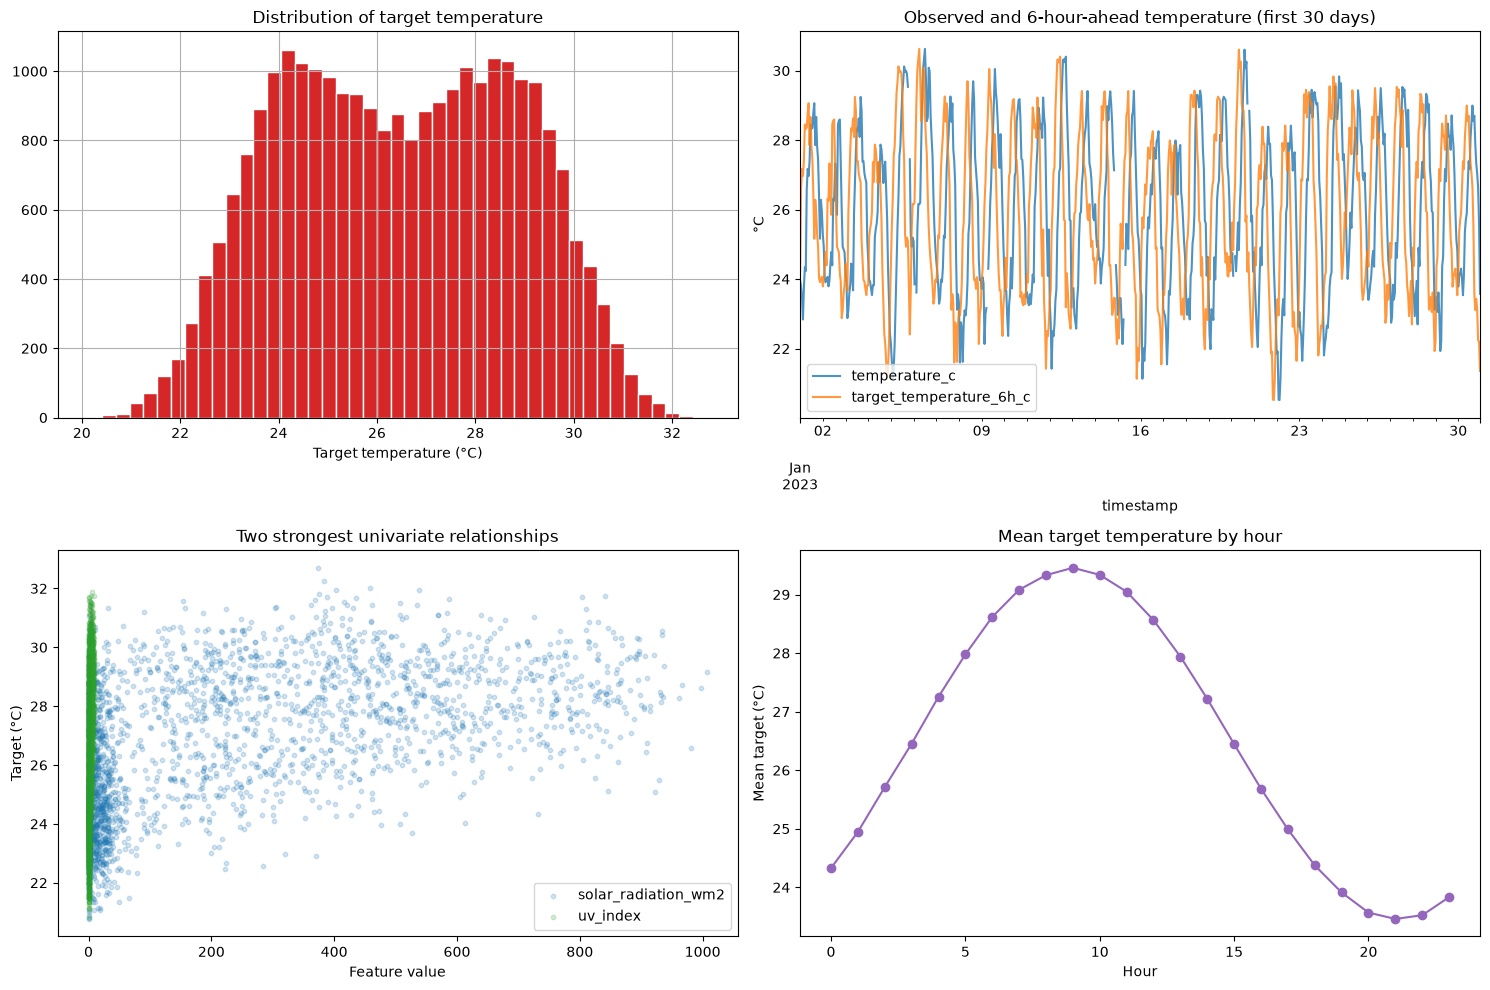

,correlation_with_target
humidity_pct,-0.102810
soil_moisture_pct,-0.082633
cloud_cover_pct,-0.071810
precipitation_mm,-0.032928
wind_speed_ms,-0.014862
wind_direction_deg,-0.003893
dew_point_c,0.038206
visibility_km,0.048857
feels_like_c,0.082836
temperature_c,0.088481


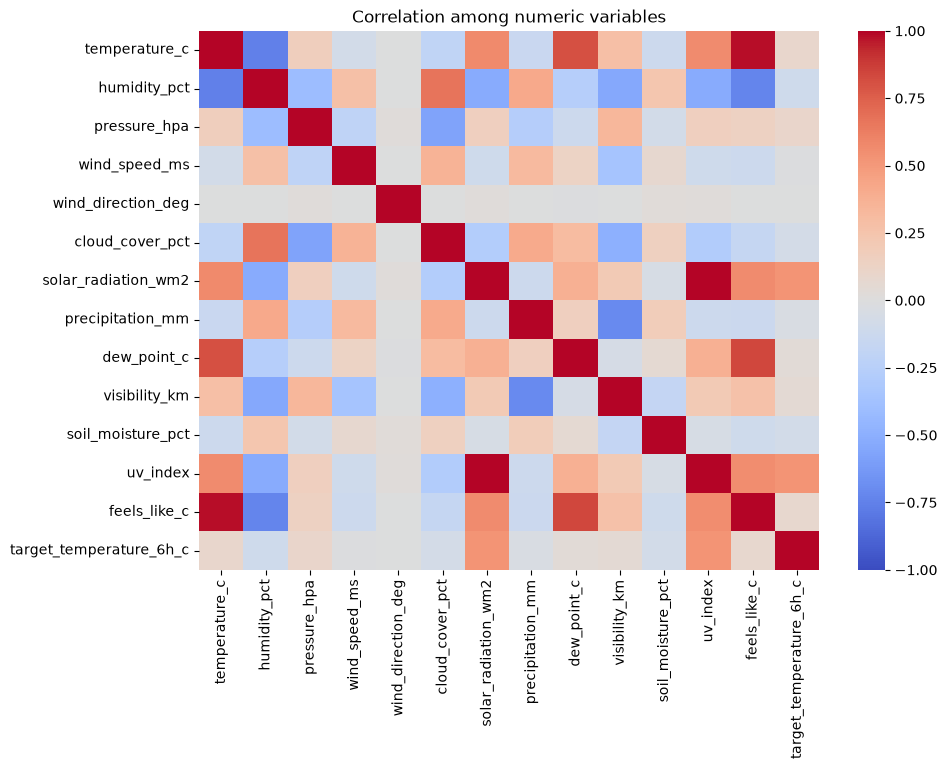

Interpretation: solar_radiation_wm2 has the largest absolute Pearson correlation with the target (r=0.530).
The hourly mean target is highest at 09:00 and lowest at 21:00; this supports cyclic time features, not a claim of causality.


,missing_count,missing_pct
solar_radiation_wm2,936,3.559206
humidity_pct,445,1.692144
temperature_c,416,1.581869
visibility_km,415,1.578067
feels_like_c,414,1.574264
precipitation_mm,408,1.551449
soil_moisture_pct,408,1.551449
dew_point_c,403,1.532436
wind_direction_deg,402,1.528633
uv_index,392,1.490608


Exact duplicate rows: 0
Duplicate timestamps: 0
Input sorted before handling: True; sorted after handling: True
Inferred frequency: h; non-hourly intervals/gaps: 0
Out-of-range values under simple physical checks: {'humidity_pct': 0, 'cloud_cover_pct': 0, 'precipitation_mm': 0, 'solar_radiation_wm2': 0, 'wind_speed_ms': 0, 'visibility_km': 0, 'uv_index': 0}
Safe treatment: chronological forward-fill will only use earlier observations; remaining missing values are median-imputed inside each training pipeline.


In [2]:
eda_df = df_clean.sort_values('timestamp').set_index('timestamp')
numeric_cols = eda_df.select_dtypes(include='number').columns.tolist()
corr_target = eda_df[numeric_cols].corr()[TARGET].sort_values()
top_features = corr_target.drop(TARGET).abs().sort_values(ascending=False).head(2).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
eda_df[TARGET].hist(bins=45, ax=axes[0, 0], color='tab:red', edgecolor='white')
axes[0, 0].set(title='Distribution of target temperature', xlabel='Target temperature (°C)')

eda_df[["temperature_c", TARGET]].iloc[:24 * 30].plot(ax=axes[0, 1], alpha=0.8)
axes[0, 1].set(title='Observed and 6-hour-ahead temperature (first 30 days)', ylabel='°C')

for feature, color in zip(top_features, ['tab:blue', 'tab:green']):
    sample = eda_df[[feature, TARGET]].dropna().sample(min(3000, eda_df[[feature, TARGET]].dropna().shape[0]), random_state=42)
    axes[1, 0].scatter(sample[feature], sample[TARGET], alpha=0.2, s=10, label=feature, color=color)
axes[1, 0].set(title='Two strongest univariate relationships', xlabel='Feature value', ylabel='Target (°C)')
axes[1, 0].legend()

hourly_target = eda_df.groupby(eda_df.index.hour)[TARGET].mean()
hourly_target.plot(ax=axes[1, 1], marker='o', color='tab:purple')
axes[1, 1].set(title='Mean target temperature by hour', xlabel='Hour', ylabel='Mean target (°C)')
plt.tight_layout()
plt.show()

display(corr_target.to_frame('correlation_with_target'))
plt.figure(figsize=(10, 7))
sns.heatmap(eda_df[numeric_cols].corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation among numeric variables')
plt.show()

peak_hour, trough_hour = hourly_target.idxmax(), hourly_target.idxmin()
print(f'Interpretation: {top_features[0]} has the largest absolute Pearson correlation with the target (r={corr_target[top_features[0]]:.3f}).')
print(f'The hourly mean target is highest at {peak_hour:02d}:00 and lowest at {trough_hour:02d}:00; this supports cyclic time features, not a claim of causality.')

# Data-quality checks
full_duplicate_count = int(df_clean.duplicated().sum())
timestamp_duplicate_count = int(df_clean['timestamp'].duplicated().sum())
is_sorted_before = df_clean['timestamp'].is_monotonic_increasing
time_sorted = df_clean.sort_values('timestamp').drop_duplicates('timestamp', keep='last').copy()
intervals = time_sorted['timestamp'].diff().dropna()
inferred_frequency = pd.infer_freq(time_sorted['timestamp'])
gap_count = int((intervals != pd.Timedelta(hours=1)).sum())

missing_table = time_sorted.isna().sum().sort_values(ascending=False).to_frame('missing_count')
missing_table['missing_pct'] = 100 * missing_table['missing_count'] / len(time_sorted)
display(missing_table)

plausibility_rules = {
    'humidity_pct': lambda s: (s < 0) | (s > 100),
    'cloud_cover_pct': lambda s: (s < 0) | (s > 100),
    'precipitation_mm': lambda s: s < 0,
    'solar_radiation_wm2': lambda s: s < 0,
    'wind_speed_ms': lambda s: s < 0,
    'visibility_km': lambda s: s < 0,
    'uv_index': lambda s: s < 0,
}
plausibility = {col: int(rule(time_sorted[col].dropna()).sum()) for col, rule in plausibility_rules.items()}

print(f'Exact duplicate rows: {full_duplicate_count}')
print(f'Duplicate timestamps: {timestamp_duplicate_count}')
print(f'Input sorted before handling: {is_sorted_before}; sorted after handling: {time_sorted.timestamp.is_monotonic_increasing}')
print(f'Inferred frequency: {inferred_frequency}; non-hourly intervals/gaps: {gap_count}')
print('Out-of-range values under simple physical checks:', plausibility)
print('Safe treatment: chronological forward-fill will only use earlier observations; remaining missing values are median-imputed inside each training pipeline.')

## Feature Engineering

`hour`, `day_of_week`, dan `month` represent kalender. `hour_sin`/`hour_cos` menjaga kedekatan jam 23 dan 0. Arah angin juga diubah ke sin/cos karena bersifat melingkar. Lag suhu 1, 2, 3, 6, 12, dan 24 jam serta rolling mean/std 3, 6, 12, dan 24 jam menangkap persistensi suhu jangka pendek hingga harian.

Rolling feature memakai `shift(1)` sebelum `rolling`, sehingga nilai pada waktu t hanya memakai suhu sebelum t; target tidak pernah dijadikan feature. Forward-fill bersifat kausal (hanya nilai masa lalu), sedangkan median imputer dan scaler nanti di-fit di pipeline training saja.

In [3]:
df = time_sorted.set_index('timestamp')
X_feature = df.drop(columns=TARGET).copy()  # target explicitly excluded from X

X_feature['hour'] = X_feature.index.hour
X_feature['day_of_week'] = X_feature.index.dayofweek
X_feature['month'] = X_feature.index.month
X_feature['is_weekend'] = (X_feature.index.dayofweek >= 5).astype(int)
X_feature['hour_sin'] = np.sin(2 * np.pi * X_feature['hour'] / 24)
X_feature['hour_cos'] = np.cos(2 * np.pi * X_feature['hour'] / 24)
X_feature['wind_dir_sin'] = np.sin(2 * np.pi * X_feature['wind_direction_deg'] / 360)
X_feature['wind_dir_cos'] = np.cos(2 * np.pi * X_feature['wind_direction_deg'] / 360)

for lag in [1, 2, 3, 6, 12, 24]:
    X_feature[f'temperature_lag_{lag}h'] = X_feature['temperature_c'].shift(lag)
for window in [3, 6, 12, 24]:
    past_temperature = X_feature['temperature_c'].shift(1).rolling(window=window, min_periods=window)
    X_feature[f'temperature_roll_mean_{window}h'] = past_temperature.mean()
    X_feature[f'temperature_roll_std_{window}h'] = past_temperature.std()

# Causal missing-value propagation; no backward fill and no interpolation from future timestamps.
X_feature = X_feature.ffill()
y = df[TARGET].copy()
assert TARGET not in X_feature.columns
assert X_feature.index.equals(y.index)

print(f'Engineered feature count: {X_feature.shape[1]}')
print(f'Rows still containing feature NaN (handled later by train-fitted median imputer): {X_feature.isna().any(axis=1).sum()}')
display(X_feature.head())

Engineered feature count: 35
Rows still containing feature NaN (handled later by train-fitted median imputer): 24


,temperature_c,humidity_pct,pressure_hpa,wind_speed_ms,wind_direction_deg,cloud_cover_pct,solar_radiation_wm2,precipitation_mm,dew_point_c,visibility_km,...,temperature_lag_12h,temperature_lag_24h,temperature_roll_mean_3h,temperature_roll_std_3h,temperature_roll_mean_6h,temperature_roll_std_6h,temperature_roll_mean_12h,temperature_roll_std_12h,temperature_roll_mean_24h,temperature_roll_std_24h
timestamp,,,,,,,,,,,,,,,,,,,,,
2023-01-01 00:00:00,23.9572,96.2405,1010.2277,2.3424,110.0000,61.1763,4.9450,0.0,23.3210,16.3343,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-01-01 01:00:00,23.7844,94.3028,1010.3044,2.1672,104.8533,49.9464,0.0000,0.0,22.8130,15.8698,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-01-01 02:00:00,23.4732,89.0114,1011.9373,2.8572,92.2816,41.3675,0.1392,0.0,21.5569,18.3136,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023-01-01 03:00:00,22.8376,95.6453,1012.4235,2.2598,99.1539,55.3739,14.9508,0.0,22.1049,18.2368,...,NaN,NaN,23.738267,0.245276,NaN,NaN,NaN,NaN,NaN,NaN
2023-01-01 04:00:00,23.7423,92.4213,1012.3489,2.0029,99.1621,47.7180,5.2828,0.0,22.4392,16.9622,...,NaN,NaN,23.365067,0.482573,NaN,NaN,NaN,NaN,NaN,NaN


## Validation Strategy

Data dibagi secara kronologis menjadi 70% training, 15% validation, dan 15% test. Proporsi ini memberikan periode training yang panjang dan dua periode masa depan yang cukup untuk seleksi dan evaluasi. Validation dipakai untuk membandingkan model; test disimpan dan hanya dibuka sekali untuk evaluasi final setelah model/hyperparameter dipilih. `TimeSeriesSplit` lima fold digunakan hanya di training untuk tuning.

In [4]:
n = len(X_feature)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

X_train, y_train = X_feature.iloc[:train_end].copy(), y.iloc[:train_end].copy()
X_valid, y_valid = X_feature.iloc[train_end:valid_end].copy(), y.iloc[train_end:valid_end].copy()
X_test, y_test = X_feature.iloc[valid_end:].copy(), y.iloc[valid_end:].copy()

assert X_train.index.max() < X_valid.index.min() < X_test.index.min()
for name, x_part in [('Train', X_train), ('Validation', X_valid), ('Test', X_test)]:
    print(f'{name:10s}: {len(x_part):,} rows | {x_part.index.min()} to {x_part.index.max()}')

tscv = TimeSeriesSplit(n_splits=5)
for fold, (tr, va) in enumerate(tscv.split(X_train), start=1):
    assert X_train.index[tr].max() < X_train.index[va].min()
    print(f'CV fold {fold}: train ends {X_train.index[tr].max()} | validation starts {X_train.index[va].min()}')

Train     : 18,408 rows | 2023-01-01 00:00:00 to 2025-02-05 23:00:00
Validation: 3,945 rows | 2025-02-06 00:00:00 to 2025-07-20 08:00:00
Test      : 3,945 rows | 2025-07-20 09:00:00 to 2025-12-31 17:00:00
CV fold 1: train ends 2023-05-08 19:00:00 | validation starts 2023-05-08 20:00:00
CV fold 2: train ends 2023-09-13 15:00:00 | validation starts 2023-09-13 16:00:00
CV fold 3: train ends 2024-01-19 11:00:00 | validation starts 2024-01-19 12:00:00
CV fold 4: train ends 2024-05-26 07:00:00 | validation starts 2024-05-26 08:00:00
CV fold 5: train ends 2024-10-01 03:00:00 | validation starts 2024-10-01 04:00:00


## Modeling

Linear Regression dipakai sebagai baseline terlatih. Naive Persistence (`T(t+6) = T(t)`) ditambahkan sebagai pembanding non-trained. Ridge, Lasso, dan Elastic Net dituning dengan `TimeSeriesSplit` lima fold pada data training. Imputer median dan `StandardScaler` berada dalam pipeline sehingga di-fit hanya pada training fold. Validation memilih model; test tidak diakses saat tuning.

In [5]:
def make_pipeline(estimator):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', estimator),
    ])

baseline = make_pipeline(LinearRegression())
baseline.fit(X_train, y_train)
baseline_valid_pred = baseline.predict(X_valid)
naive_valid_pred = X_valid['temperature_c'].to_numpy()  # persistence: predict T(t+6) as T(t)
baseline_metrics = {
    'model': 'Linear Regression',
    'rmse': np.sqrt(mean_squared_error(y_valid, baseline_valid_pred)),
    'mae': mean_absolute_error(y_valid, baseline_valid_pred),
    'r2': r2_score(y_valid, baseline_valid_pred),
    'best_params': {},
}
naive_validation_metrics = {
    'model': 'Naive Persistence',
    'rmse': np.sqrt(mean_squared_error(y_valid, naive_valid_pred)),
    'mae': mean_absolute_error(y_valid, naive_valid_pred),
    'r2': r2_score(y_valid, naive_valid_pred),
    'best_params': 'not applicable',
}
print('Baseline validation metrics:', baseline_metrics)
print('Naive Persistence validation metrics:', naive_validation_metrics)

# Time-series tuning of allowed linear models
search_specs = {
    'Ridge': (Ridge(), {'model__alpha': [0.01, 0.1, 1, 10, 100]}),
    'Lasso': (Lasso(max_iter=20000), {'model__alpha': [0.001, 0.01, 0.1, 1]}),
    'Elastic Net': (ElasticNet(max_iter=20000), {'model__alpha': [0.001, 0.01, 0.1, 1], 'model__l1_ratio': [0.1, 0.5, 0.9]}),
}

fitted_validation_models = {'Linear Regression': baseline}
comparison_rows = [baseline_metrics]
for name, (estimator, grid) in search_specs.items():
    search = GridSearchCV(
        make_pipeline(estimator), grid, cv=tscv,
        scoring='neg_root_mean_squared_error', n_jobs=1,
    )
    search.fit(X_train, y_train)
    pred = search.predict(X_valid)
    fitted_validation_models[name] = search
    comparison_rows.append({
        'model': name,
        'rmse': np.sqrt(mean_squared_error(y_valid, pred)),
        'mae': mean_absolute_error(y_valid, pred),
        'r2': r2_score(y_valid, pred),
        'best_params': search.best_params_,
        'cv_rmse': -search.best_score_,
    })

comparison = pd.DataFrame(comparison_rows).sort_values('rmse').reset_index(drop=True)
display(comparison)
selected_name = comparison.loc[0, 'model']
selected_params = comparison.loc[0, 'best_params']
print(f'Selected using validation only: {selected_name} with {selected_params}')

# Validation comparison, including Naive Persistence
validation_comparison = pd.concat([pd.DataFrame([naive_validation_metrics]), comparison], ignore_index=True)
display(validation_comparison[['model', 'rmse', 'mae', 'r2', 'best_params']].style.format({'rmse': '{:.6f}', 'mae': '{:.6f}', 'r2': '{:.6f}'}))
print('Naive Persistence is a benchmark only; selection among permitted trained models uses the four linear models above.')

Baseline validation metrics:

 {'model': 'Linear Regression', 'rmse': np.float64(0.9076645878867563), 'mae': 0.7233497795057546, 'r2': 0.8415353764807909, 'best_params': {}}
Naive Persistence validation metrics: {'model': 'Naive Persistence', 'rmse': np.float64(3.1355948964860647), 'mae': 2.7422487198986056, 'r2': -0.8911302304489888, 'best_params': 'not applicable'}


,model,rmse,mae,r2,best_params,cv_rmse
0,Linear Regression,0.907665,0.723350,0.841535,{},NaN
1,Ridge,0.907665,0.723350,0.841535,{'model__alpha': 0.01},0.996729
2,Elastic Net,0.910730,0.725828,0.840463,"{'model__alpha': 0.01, 'model__l1_ratio': 0.9}",0.989571
3,Lasso,0.910906,0.725957,0.840402,{'model__alpha': 0.01},0.989388


Selected using validation only: Linear Regression with {}


,model,rmse,mae,r2,best_params
0,Naive Persistence,3.135595,2.742249,-0.891130,not applicable
1,Linear Regression,0.907665,0.723350,0.841535,{}
2,Ridge,0.907665,0.723350,0.841535,{'model__alpha': 0.01}
3,Elastic Net,0.910730,0.725828,0.840463,"{'model__alpha': 0.01, 'model__l1_ratio': 0.9}"
4,Lasso,0.910906,0.725957,0.840402,{'model__alpha': 0.01}


Naive Persistence is a benchmark only; selection among permitted trained models uses the four linear models above.


# Findings

Temuan berikut dihasilkan dari nilai aktual yang dihitung pada cell evidence, bukan dari contoh atau asumsi.

## Finding A

### Chart / Bukti

Tabel korelasi dan heatmap pada Data Overview menjadi bukti untuk finding ini.

In [6]:
top_corr_feature = corr_target.drop(TARGET).abs().idxmax()
print(f'Feature with the largest absolute correlation to target: {top_corr_feature} (r={corr_target[top_corr_feature]:.3f})')

Feature with the largest absolute correlation to target: solar_radiation_wm2 (r=0.530)


### Key point

Nilai korelasi aktual dicetak di atas.

### Why

Korelasi memberi bukti hubungan linear univariat, tetapi model tetap dievaluasi memakai seluruh fitur dan bukan korelasi saja.

## Finding B

### Chart / Bukti

Plot rata-rata target menurut jam pada Data Overview menjadi bukti pola temporal.

In [7]:
peak_hour, trough_hour = hourly_target.idxmax(), hourly_target.idxmin()
print(f'Mean target is highest at {peak_hour:02d}:00 and lowest at {trough_hour:02d}:00.')

Mean target is highest at 09:00 and lowest at 21:00.


### Key point

Jam dengan rata-rata target tertinggi dan terendah dicetak di atas.

### Why

Pola intrahari yang terlihat mendukung fitur hour sin/cos, yang menjaga kedekatan antara jam 23 dan 00.

## Finding C

### Chart / Bukti

Tabel model comparison menunjukkan RMSE validation untuk pemilihan model dan RMSE test untuk evaluasi akhir.

In [8]:
print(f'Selected by validation: {selected_name} with {selected_params}')
print('Validation comparison (RMSE):')
display(validation_comparison[['model', 'rmse']].sort_values('rmse'))

Selected by validation: Linear Regression with {}
Validation comparison (RMSE):


,model,rmse
1,Linear Regression,0.907665
2,Ridge,0.907665
3,Elastic Net,0.910730
4,Lasso,0.910906
0,Naive Persistence,3.135595


### Key point

Model dipilih berdasarkan validation, bukan test set.

### Why

Memisahkan selection dan final test menjaga estimasi generalisasi tetap lebih jujur serta mencegah test-set leakage.

## Results

Setelah model/hyperparameter dipilih di validation, seluruh model linear yang diizinkan dievaluasi pada test set. Model terpilih di-fit ulang pada gabungan train+validation sebelum test. Plot Actual vs Predicted menggunakan model terpilih berdasarkan validation.

,Final test - Linear Regression
RMSE (°C),0.887419
MAE (°C),0.707288
R²,0.852553


Interpretation: RMSE 0.887 °C is the typical error scale with extra penalty for larger temperature misses; it does not mean the model is perfectly accurate.


,model,rmse,mae,r2
0,Elastic Net,0.885705,0.706772,0.853122
1,Lasso,0.885706,0.706764,0.853121
2,Ridge,0.887419,0.707288,0.852553
3,Linear Regression,0.887419,0.707288,0.852553
4,Naive Persistence,3.166409,2.763817,-0.877212


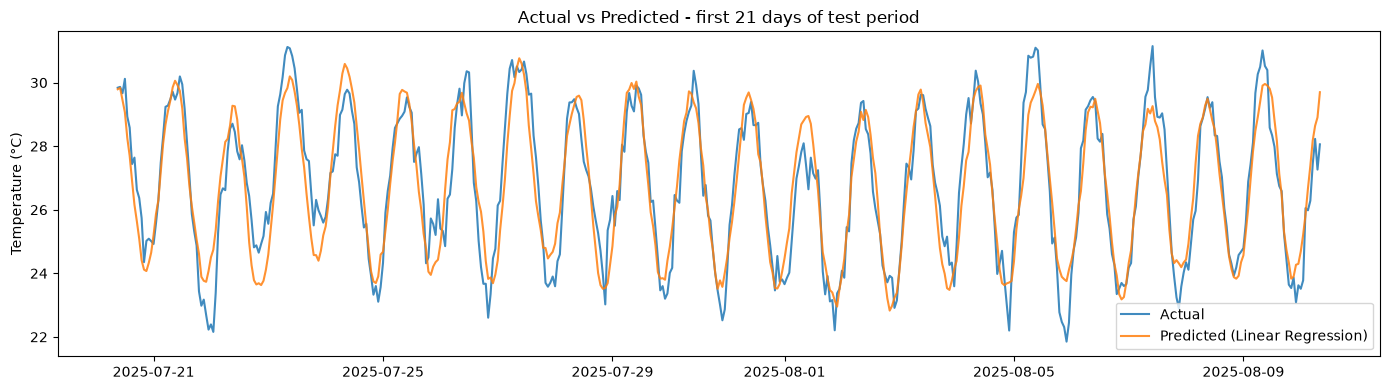

In [9]:
X_train_valid = pd.concat([X_train, X_valid])
y_train_valid = pd.concat([y_train, y_valid])

if selected_name == 'Linear Regression':
    final_estimator = LinearRegression()
elif selected_name == 'Ridge':
    final_estimator = Ridge(alpha=selected_params['model__alpha'])
elif selected_name == 'Lasso':
    final_estimator = Lasso(alpha=selected_params['model__alpha'], max_iter=20000)
else:
    final_estimator = ElasticNet(
        alpha=selected_params['model__alpha'],
        l1_ratio=selected_params['model__l1_ratio'],
        max_iter=20000,
    )

final_model = make_pipeline(final_estimator)
final_model.fit(X_train_valid, y_train_valid)
test_pred = final_model.predict(X_test)
final_metrics = {
    'RMSE (°C)': np.sqrt(mean_squared_error(y_test, test_pred)),
    'MAE (°C)': mean_absolute_error(y_test, test_pred),
    'R²': r2_score(y_test, test_pred),
}
display(pd.DataFrame([final_metrics], index=[f'Final test - {selected_name}']).T)
print(f"Interpretation: RMSE {final_metrics['RMSE (°C)']:.3f} °C is the typical error scale with extra penalty for larger temperature misses; it does not mean the model is perfectly accurate.")

# Evaluate the naive baseline and every permitted linear model on the untouched test period.
def estimator_from_row(row):
    if row['model'] == 'Linear Regression':
        return LinearRegression()
    if row['model'] == 'Ridge':
        return Ridge(alpha=row['best_params']['model__alpha'])
    if row['model'] == 'Lasso':
        return Lasso(alpha=row['best_params']['model__alpha'], max_iter=20000)
    return ElasticNet(alpha=row['best_params']['model__alpha'], l1_ratio=row['best_params']['model__l1_ratio'], max_iter=20000)

test_rows = [{
    'model': 'Naive Persistence',
    'rmse': np.sqrt(mean_squared_error(y_test, X_test['temperature_c'])),
    'mae': mean_absolute_error(y_test, X_test['temperature_c']),
    'r2': r2_score(y_test, X_test['temperature_c']),
}]
for _, row in comparison.iterrows():
    candidate = make_pipeline(estimator_from_row(row))
    candidate.fit(X_train_valid, y_train_valid)
    candidate_pred = candidate.predict(X_test)
    test_rows.append({
        'model': row['model'],
        'rmse': np.sqrt(mean_squared_error(y_test, candidate_pred)),
        'mae': mean_absolute_error(y_test, candidate_pred),
        'r2': r2_score(y_test, candidate_pred),
    })
test_comparison = pd.DataFrame(test_rows).sort_values('rmse').reset_index(drop=True)
display(test_comparison.style.format({'rmse': '{:.6f}', 'mae': '{:.6f}', 'r2': '{:.6f}'}))

plt.figure(figsize=(14, 4))
plt.plot(y_test.index[:24 * 21], y_test.iloc[:24 * 21], label='Actual', alpha=0.85)
plt.plot(y_test.index[:24 * 21], test_pred[:24 * 21], label=f'Predicted ({selected_name})', alpha=0.85)
plt.title('Actual vs Predicted - first 21 days of test period')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.tight_layout()
plt.show()


## Error Analysis

Residual pada test set dianalisis melalui residual-vs-predicted, distribusi residual, MAE menurut jam, dan observasi dengan 5% absolute error tertinggi. Interpretasi dibatasi pada pola yang muncul pada output.

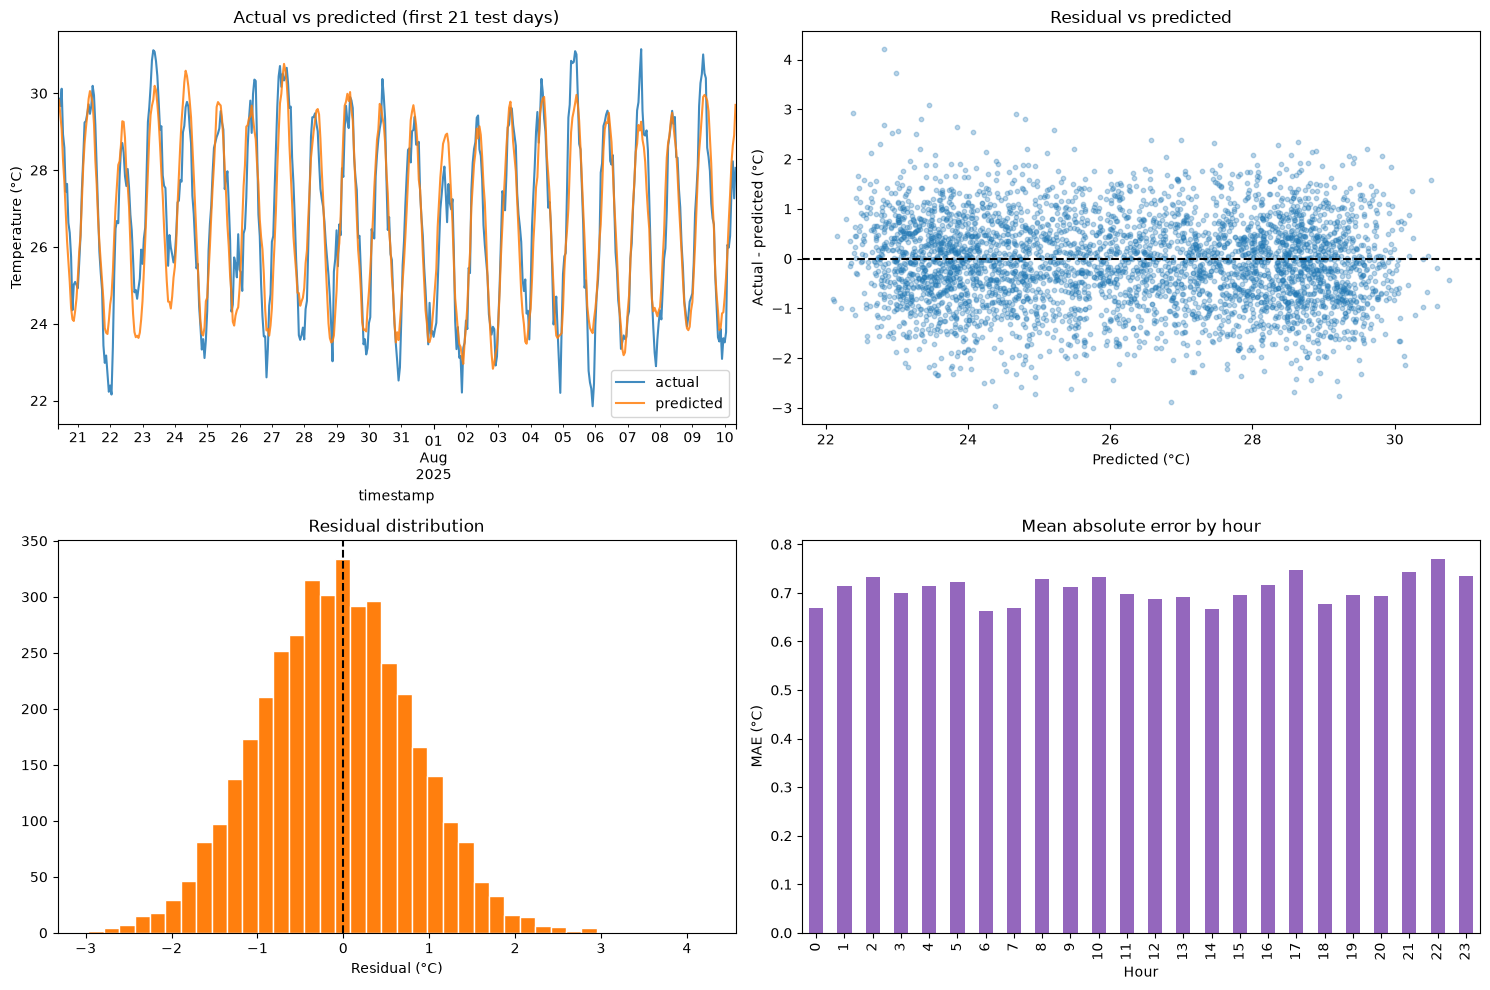

,actual,predicted,residual,abs_error,hour,humidity_pct,precipitation_mm,wind_speed_ms,temperature_c
timestamp,,,,,,,,,
2025-08-22 21:00:00,27.0318,22.824388,4.207412,4.207412,21,93.0951,0.309,3.5869,25.5985
2025-08-22 22:00:00,26.7099,22.985049,3.724851,3.724851,22,99.0852,NaN,3.1068,24.5527
2025-11-02 23:00:00,26.5291,23.451109,3.077991,3.077991,23,85.8854,0.000,1.0837,24.4789
2025-08-24 23:00:00,21.4071,24.374314,-2.967214,2.967214,23,89.0548,0.259,2.2309,24.9090
2025-11-02 21:00:00,25.3017,22.377425,2.924275,2.924275,21,91.8995,0.000,2.0654,24.2998
2025-08-23 00:00:00,27.5868,24.672618,2.914182,2.914182,0,84.1743,0.000,5.5498,25.6253
2025-11-15 04:00:00,23.9742,26.852955,-2.878755,2.878755,4,100.0000,6.353,3.2940,22.4624
2025-11-03 01:00:00,27.6079,24.795422,2.812478,2.812478,1,98.0373,1.789,2.9728,23.1920
2025-08-22 19:00:00,26.1498,23.339325,2.810475,2.810475,19,81.0058,0.000,5.4240,27.1475


Largest mean hourly MAE: 22:00, 0.770 °C.
Large-error threshold (test P95): 1.717 °C; observations at/above threshold: 198.


In [10]:
test_eval = pd.DataFrame({'actual': y_test, 'predicted': test_pred}, index=y_test.index)
test_eval['residual'] = test_eval['actual'] - test_eval['predicted']
test_eval['abs_error'] = test_eval['residual'].abs()
test_eval['hour'] = test_eval.index.hour
test_eval = test_eval.join(df[['humidity_pct', 'precipitation_mm', 'wind_speed_ms', 'temperature_c']], how='left')

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
test_eval[['actual', 'predicted']].iloc[:24 * 21].plot(ax=axes[0, 0], alpha=0.85)
axes[0, 0].set(title='Actual vs predicted (first 21 test days)', ylabel='Temperature (°C)')
axes[0, 1].scatter(test_eval['predicted'], test_eval['residual'], alpha=0.3, s=10)
axes[0, 1].axhline(0, color='black', linestyle='--')
axes[0, 1].set(title='Residual vs predicted', xlabel='Predicted (°C)', ylabel='Actual - predicted (°C)')
axes[1, 0].hist(test_eval['residual'], bins=40, color='tab:orange', edgecolor='white')
axes[1, 0].axvline(0, color='black', linestyle='--')
axes[1, 0].set(title='Residual distribution', xlabel='Residual (°C)')
hourly_mae = test_eval.groupby('hour')['abs_error'].agg(['mean', 'median', 'count'])
hourly_mae['mean'].plot(kind='bar', ax=axes[1, 1], color='tab:purple')
axes[1, 1].set(title='Mean absolute error by hour', xlabel='Hour', ylabel='MAE (°C)')
plt.tight_layout()
plt.show()

large_error_threshold = test_eval['abs_error'].quantile(0.95)
large_errors = test_eval[test_eval['abs_error'] >= large_error_threshold].sort_values('abs_error', ascending=False)
display(large_errors.head(15))
print(f'Largest mean hourly MAE: {hourly_mae["mean"].idxmax():02d}:00, {hourly_mae["mean"].max():.3f} °C.')
print(f'Large-error threshold (test P95): {large_error_threshold:.3f} °C; observations at/above threshold: {len(large_errors)}.')

# Discussion & Limitations

- Dataset bersifat sintetis; pola, noise, dan missingness dapat berbeda dari pengukuran stasiun nyata.
- Assessment membatasi model pada regresi linear, sehingga interaksi non-linear cuaca tidak dieksplorasi.
- Lag dan rolling feature membutuhkan observasi historis; deployment perlu mempertahankan penanganan missing value yang kausal.
- Performa test hanya mewakili periode pada dataset ini dan dapat berubah bila distribusi cuaca berubah.

# Summary

Notebook selesai dijalankan dengan split kronologis 70% train, 15% validation, dan 15% test. Audit leakage: target tidak masuk feature matrix; lag/rolling memakai masa lalu; imputer/scaler di-fit dalam pipeline training; tuning memakai `TimeSeriesSplit`; test tidak dipakai untuk memilih model; dan tidak ada random split atau model di luar empat estimator linear yang diizinkan.

Lihat bagian **Results** untuk metrik final aktual dan bagian **Error Analysis** untuk batasan empiris model.